In [ ]:
import numpy as np
import pandas as pd
import datetime
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import colors
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler
from sklearn.decomposition import PCA
from yellowbrick.cluster import KElbowVisualizer
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt, numpy as np
from mpl_toolkits.mplot3d import Axes3D
from sklearn.cluster import AgglomerativeClustering
from matplotlib.colors import ListedColormap
from sklearn import metrics
import warnings
import sys
if not sys.warnoptions:
    warnings.simplefilter("ignore")
np.random.seed(42)

import warnings
warnings.filterwarnings('ignore')
from sklearn.cluster import AffinityPropagation
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams['font.family'] = 'DejaVu Sans'
mpl.rcParams['axes.unicode_minus'] = False

In [ ]:
!gdown 1nrZqblTbq9PHYvafZIi9giisKIdXmn34

Downloading...
From: https://drive.google.com/uc?id=1nrZqblTbq9PHYvafZIi9giisKIdXmn34
To: /content/raw.csv
100% 218k/218k [00:00<00:00, 88.5MB/s]


In [ ]:
df = pd.read_csv(r'/content/raw.csv')
df

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,4/9/2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,8/3/2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21/8/2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10/2/2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19/1/2014,94,173,...,5,0,0,0,0,0,0,3,11,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,10870,1967,Graduation,Married,61223.0,0,1,13/6/2013,46,709,...,5,0,0,0,0,0,0,3,11,0
2236,4001,1946,PhD,Together,64014.0,2,1,10/6/2014,56,406,...,7,0,0,0,1,0,0,3,11,0
2237,7270,1981,Graduation,Divorced,56981.0,0,0,25/1/2014,91,908,...,6,0,1,0,0,0,0,3,11,0
2238,8235,1956,Master,Together,69245.0,0,1,24/1/2014,8,428,...,3,0,0,0,0,0,0,3,11,0


In [ ]:
colors = sns.color_palette("deep")
colors

[(0.2980392156862745, 0.4470588235294118, 0.6901960784313725),
 (0.8666666666666667, 0.5176470588235295, 0.3215686274509804),
 (0.3333333333333333, 0.6588235294117647, 0.40784313725490196),
 (0.7686274509803922, 0.3058823529411765, 0.3215686274509804),
 (0.5058823529411764, 0.4470588235294118, 0.7019607843137254),
 (0.5764705882352941, 0.47058823529411764, 0.3764705882352941),
 (0.8549019607843137, 0.5450980392156862, 0.7647058823529411),
 (0.5490196078431373, 0.5490196078431373, 0.5490196078431373),
 (0.8, 0.7254901960784313, 0.4549019607843137),
 (0.39215686274509803, 0.7098039215686275, 0.803921568627451)]

###Xử lí nhanh

In [ ]:
df = df.drop(columns=['Z_CostContact', 'Z_Revenue','ID'])

In [ ]:
# chỉ có 1 giá trị 800.000 còn lại dưới 200.000
df['Income'].fillna(df['Income'].median(), inplace=True)
df = df[df.Income <= 200000]

People

In [ ]:
# chuyển Year-Birth thành tuổi
df['Year_Birth']= 2025 - df['Year_Birth']
df.Year_Birth

,Year_Birth
0,68
1,71
2,60
3,41
4,44
...,...
2235,58
2236,79
2237,44
2238,69


In [ ]:
df =df[df.Year_Birth<=90]

In [ ]:
df.Marital_Status = df.Marital_Status.replace(['Alone', 'YOLO'], 'Single')
# bỏ giá trị Absurd vì số lượng nhỏ và không có ý nghĩa
df = df[df.Marital_Status != 'Absurd']
df.Marital_Status.value_counts()

,count
Marital_Status,
Married,864
Together,578
Single,484
Divorced,231
Widow,77


In [ ]:
df['Children'] = df['Kidhome'] + df['Teenhome']
df.drop(columns=['Kidhome', 'Teenhome'], inplace=True)

In [ ]:
df['Dt_Customer']= pd.to_datetime(df['Dt_Customer'], format='%d/%m/%Y')

# chuyển thành số tháng từ khi đăng kí đến nay
df['Customer_for'] = (datetime.datetime.now() - df['Dt_Customer']).dt.days // 30
df.drop(columns=['Dt_Customer'], inplace=True)

In [ ]:
df.Complain.value_counts()
# có 19 người khiếu nại thôi nên loại bỏ
df = df.drop(columns=['Complain'])

Product

Promotion

In [ ]:
#gom thành 3 nhóm cho hợp lí 1: mua ít, 2: mua vừa, 3: mua nhiều
def categorize_deals_purchases(x):
    if x <= 2:
        return 1
    elif x <= 5:
        return 2
    else:
        return 3

df['NumDealsPurchases'] = df['NumDealsPurchases'].apply(categorize_deals_purchases)

In [ ]:
df = df.drop(columns=['AcceptedCmp1','AcceptedCmp2','AcceptedCmp3','AcceptedCmp4','AcceptedCmp5','Response'])

Place

Code cũ cell trước có in ra số lượng OUTLIER không nhiều nên khỏi bỏ luôn. Với outlier đó hợp logic ngoài đời nên không bỏ


In [ ]:
# #số lượng outliers không nhiều, bỏ đi hợp lí và giúp giảm nhiễu
# place = [
#     'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases',
#     'NumWebVisitsMonth'
# ]
# for col in place:
#     Q1 = df[col].quantile(0.25)
#     Q3 = df[col].quantile(0.75)
#     IQR = Q3 - Q1
#     lower_bound = Q1 - 1.5 * IQR
#     upper_bound = Q3 + 1.5 * IQR
#     df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

### Chuẩn hóa

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2234 entries, 0 to 2239
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Year_Birth           2234 non-null   int64  
 1   Education            2234 non-null   object 
 2   Marital_Status       2234 non-null   object 
 3   Income               2234 non-null   float64
 4   Recency              2234 non-null   int64  
 5   MntWines             2234 non-null   int64  
 6   MntFruits            2234 non-null   int64  
 7   MntMeatProducts      2234 non-null   int64  
 8   MntFishProducts      2234 non-null   int64  
 9   MntSweetProducts     2234 non-null   int64  
 10  MntGoldProds         2234 non-null   int64  
 11  NumDealsPurchases    2234 non-null   int64  
 12  NumWebPurchases      2234 non-null   int64  
 13  NumCatalogPurchases  2234 non-null   int64  
 14  NumStorePurchases    2234 non-null   int64  
 15  NumWebVisitsMonth    2234 non-null   int64 

In [ ]:
num = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
cate = df.select_dtypes(include=['object']).columns.tolist()

In [ ]:
education_order = ['Basic', '2n Cycle', 'Graduation', 'Master', 'PhD']

education_mapping = {level: idx for idx, level in enumerate(education_order)}

df['Education'] = df['Education'].map(education_mapping)

In [ ]:
df = pd.get_dummies(df, columns=['Marital_Status'], drop_first=True)

In [ ]:
binary_cols = []
continuous_cols = []

for col in num:
    uniq = df[col].dropna().unique()
    if len(uniq) == 2 and set(uniq) == {0, 1}:
        binary_cols.append(col)
    else:
        continuous_cols.append(col)

print("Binary columns:", binary_cols)
print("Continuous columns:", continuous_cols)


Binary columns: []
Continuous columns: ['Year_Birth', 'Income', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'Children', 'Customer_for']


In [ ]:
# Không có biến binary, nên dùng scale bằng Robust do nhiều Outliers
df_scaled = df.copy()
scaler = RobustScaler()

df_scaled[continuous_cols] = scaler.fit_transform(df[continuous_cols])

In [ ]:
ap = AffinityPropagation(damping=0.9, random_state=42,preference = -3000)  #3 cum thi -2200
labels = ap.fit_predict(df_scaled)

n_clusters = len(set(labels))

if n_clusters > 1:
    ap_sil_score = silhouette_score(df_scaled, labels, metric='euclidean')
else:
    ap_sil_score = None

print(f"Số cluster tìm được: {n_clusters}")
print(f"Silhouette Score: {ap_sil_score}")

df_scaled['AP_Cluster'] = labels

Số cluster tìm được: 2
Silhouette Score: 0.3526801260101285


### PCA

In [ ]:
data = df_scaled.copy()

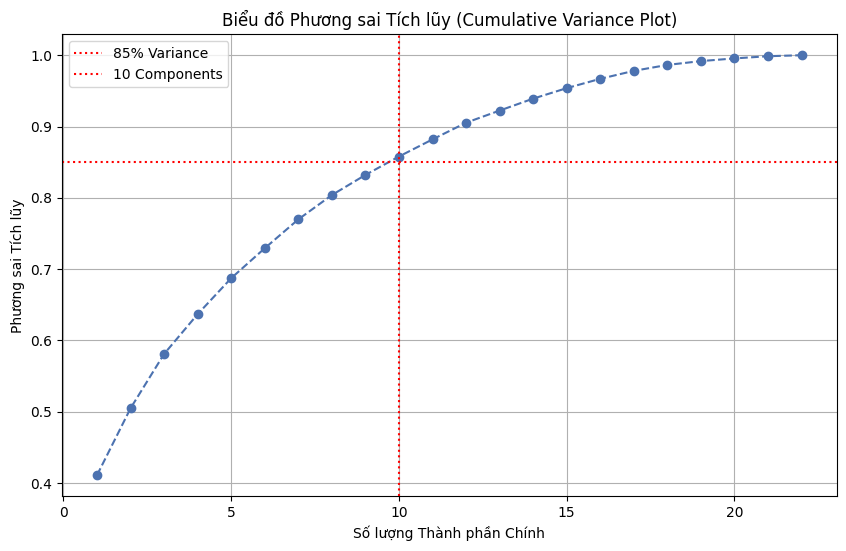

Số thành phần cần thiết để giữ 80% phương sai: 10


In [ ]:
pca_full = PCA(n_components=None)
pca_full.fit(data)

cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

k = np.argmax(cumulative_variance >= 0.85) + 1

plt.figure(figsize=(10, 6))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--', color=colors[0])
plt.title('Biểu đồ Phương sai Tích lũy (Cumulative Variance Plot)')
plt.xlabel('Số lượng Thành phần Chính')
plt.ylabel('Phương sai Tích lũy')
plt.grid(True)

plt.axhline(y=0.85, color='red', linestyle=':', label='85% Variance')
plt.axvline(x=k, color='red', linestyle=':', label=f'{k} Components')
plt.legend(loc='best')
plt.show()

print(f"Số thành phần cần thiết để giữ 80% phương sai: {k}")

In [ ]:
k_components = 10

pca_final = PCA(n_components=k_components)
X_pca = pca_final.fit_transform(data)

print(f"Đã giảm chiều dữ liệu từ {data.shape[1]} xuống {X_pca.shape[1]} thành phần.")

Đã giảm chiều dữ liệu từ 22 xuống 10 thành phần.


Đang chạy Affinity Propagation (AP) trên dữ liệu PCA...
Việc này có thể mất vài phút...
Số cụm (exemplars) tìm thấy: 2
Silhouette Score: 0.4059


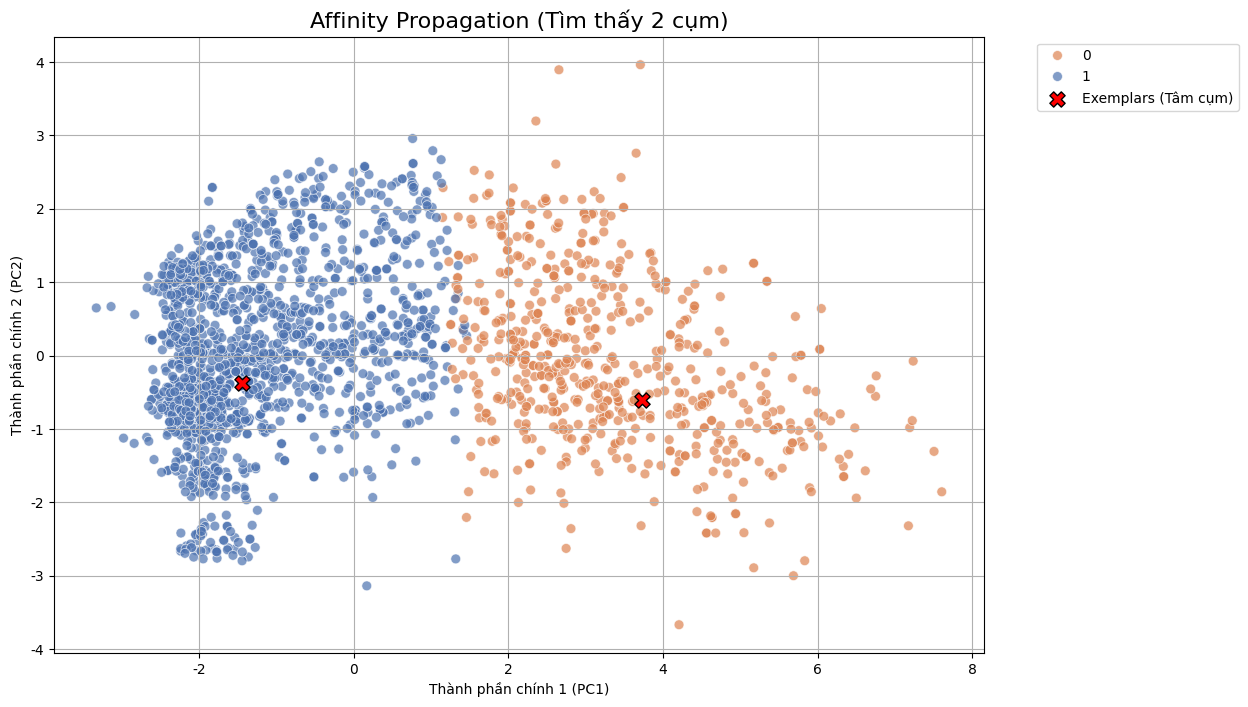

In [ ]:
from sklearn.cluster import AffinityPropagation
from sklearn.metrics import silhouette_score
import time

print("Đang chạy Affinity Propagation (AP) trên dữ liệu PCA...")
print("Việc này có thể mất vài phút...")
start_time = time.time()

ap = AffinityPropagation(damping=0.9, random_state=42, preference=-1800)

ap.fit(X_pca)

end_time = time.time()

ap_labels = ap.labels_
ap_centers_indices = ap.cluster_centers_indices_
ap_n_clusters = len(ap_centers_indices)

# print(f"\nAP hoàn tất sau {end_time - start_time:.2f} giây.")
print(f"Số cụm (exemplars) tìm thấy: {ap_n_clusters}")


if ap_n_clusters > 1:
    ap_sil_score1 = silhouette_score(X_pca, ap_labels)
    print(f"Silhouette Score: {ap_sil_score1:.4f}")
else:
    print("AP chỉ tìm thấy 1 cụm, không thể tính Silhouette Score.")


ap_centers_pca = ap.cluster_centers_

df_pca_results = pd.DataFrame(X_pca, columns=[f'PC{i+1}' for i in range(k_components)])
df_pca_results['AP_Cluster'] = ap_labels

plt.figure(figsize=(12, 8))
sns.scatterplot(data=df_pca_results, x='PC1', y='PC2', hue='AP_Cluster',
                palette=[colors[1], colors[0]], legend='full', s=50, alpha=0.7)

plt.scatter(ap_centers_pca[:, 0], ap_centers_pca[:, 1], s=120, c='red',
            marker='X', label='Exemplars (Tâm cụm)', edgecolors='black')

plt.title(f'Affinity Propagation (Tìm thấy {ap_n_clusters} cụm)', fontsize=16)
plt.xlabel('Thành phần chính 1 (PC1)')
plt.ylabel('Thành phần chính 2 (PC2)')
plt.legend(bbox_to_anchor=(1.05, 1), loc=2)
plt.grid(True)
plt.show()

# So sánh với KMeans

dùng elbow


In [ ]:
nbClusters = range(1, 13)
scores = []
for k in nbClusters:
    model = KMeans(n_clusters = k)
    model.fit(X_pca)
    scores.append(model.inertia_)

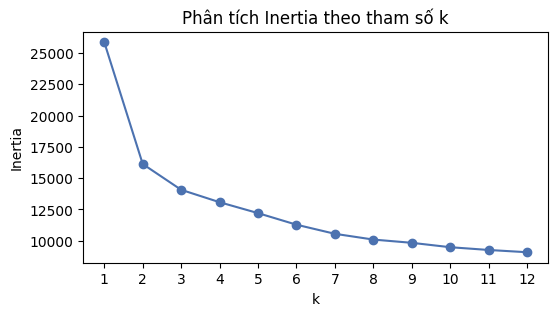

In [ ]:
plt.figure(figsize = (6, 3))
plt.plot(nbClusters, scores, 'bo-', color=colors[0])
plt.xlabel('k')
plt.xticks(nbClusters)
plt.ylabel('Inertia')
plt.title('Phân tích Inertia theo tham số k')

plt.show()

In [ ]:
k     = 2 # chọn k =2 dựa trên biểu đồ phân tích inertia
model = KMeans(n_clusters = k)
model.fit(X_pca)

KMeans(n_clusters=2)

In [ ]:
print(f'*** {k} trọng tâm:')
print(model.cluster_centers_)

*** 2 trọng tâm:
[[-1.40853935e+00 -6.08653137e-03  6.43335187e-02  3.26310437e-02
   2.29638614e-02  4.49182593e-03 -5.59353380e-03 -1.07153419e-03
  -1.15750989e-02  6.09793538e-04]
 [ 3.08030075e+00  1.33104887e-02 -1.40689421e-01 -7.13600429e-02
  -5.02191149e-02 -9.82306583e-03  1.22323642e-02  2.34331229e-03
   2.53133047e-02 -1.33354279e-03]]


In [ ]:
df['KMeans_cluster'] = model.labels_
print(df.head())

print('\nKích thước các clusters:')
print(pd.Series(model.labels_).value_counts())
print(f'Inertia / #samples = {model.inertia_/df.shape[0]:.2f}')

   Year_Birth  Education   Income  Recency  MntWines  MntFruits  \
0          68          2  58138.0       58       635         88   
1          71          2  46344.0       38        11          1   
2          60          2  71613.0       26       426         49   
3          41          2  26646.0       26        11          4   
4          44          4  58293.0       94       173         43   

   MntMeatProducts  MntFishProducts  MntSweetProducts  MntGoldProds  ...  \
0              546              172                88            88  ...   
1                6                2                 1             6  ...   
2              127              111                21            42  ...   
3               20               10                 3             5  ...   
4              118               46                27            15  ...   

   NumCatalogPurchases  NumStorePurchases  NumWebVisitsMonth  Children  \
0                   10                  4                  7      

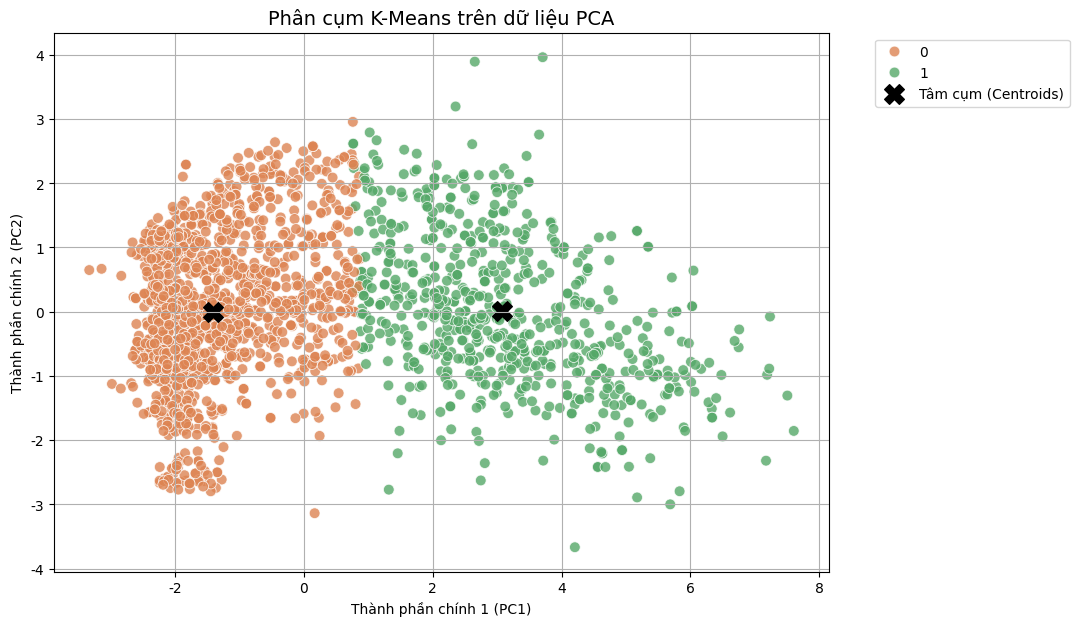

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

df_pca_kmeans = pd.DataFrame(X_pca, columns=[f'PC{i+1}' for i in range(X_pca.shape[1])])
df_pca_kmeans['cluster'] = model.labels_

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=df_pca_kmeans,
    x='PC1', y='PC2',
    hue='cluster',
    palette=[colors[1], colors[2]],
    s=60,
    alpha=0.8
)

centers = model.cluster_centers_
plt.scatter(
    centers[:, 0], centers[:, 1],
    c='black', s=200, marker='X', label='Tâm cụm (Centroids)'
)

plt.title('Phân cụm K-Means trên dữ liệu PCA', fontsize=14)
plt.xlabel('Thành phần chính 1 (PC1)')
plt.ylabel('Thành phần chính 2 (PC2)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.show()


dùng Silhouette

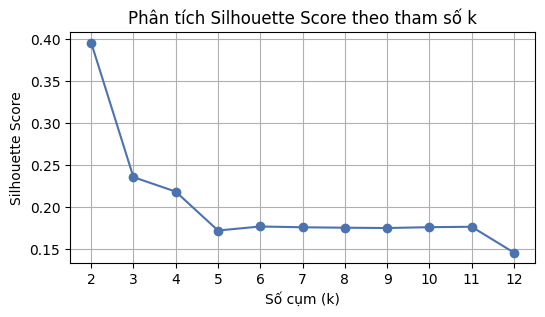

Giá trị tối ưu cho k: 2


In [ ]:
nbClusters  = range(2, 13)
silhouettes = []

for k in nbClusters:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_pca)
    kmeans_sil_score = silhouette_score(X_pca, labels, metric='euclidean')
    silhouettes.append(kmeans_sil_score)

plt.figure(figsize=(6, 3))
plt.plot(nbClusters, silhouettes, 'bo-', color=colors[0])
plt.xlabel('Số cụm (k)')
plt.xticks(nbClusters)
plt.ylabel('Silhouette Score')
plt.title('Phân tích Silhouette Score theo tham số k')
plt.grid(True)
plt.show()

print(f'Giá trị tối ưu cho k: {nbClusters[np.argmax(silhouettes)]}')


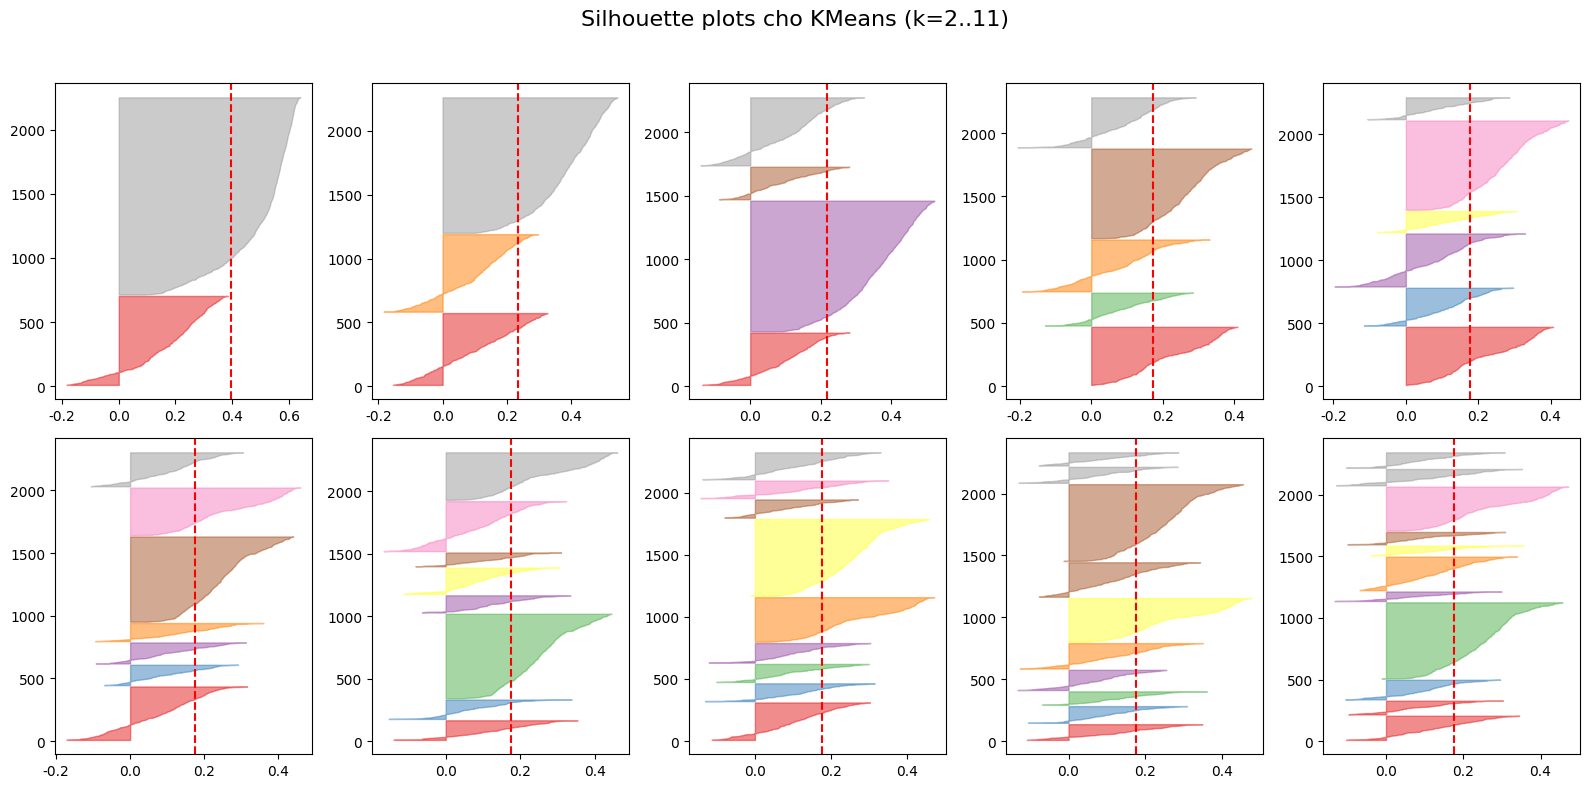

In [ ]:
from yellowbrick.cluster import SilhouetteVisualizer

nbClusters = range(2, 12)
fig, ax = plt.subplots(2, 5, figsize=(16, 8))

for k in nbClusters:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    row, col = divmod(k - 2, 5)

    visualizer = SilhouetteVisualizer(model, ax=ax[row][col])
    visualizer.fit(X_pca)

fig.suptitle("Silhouette plots cho KMeans (k=2..11)", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

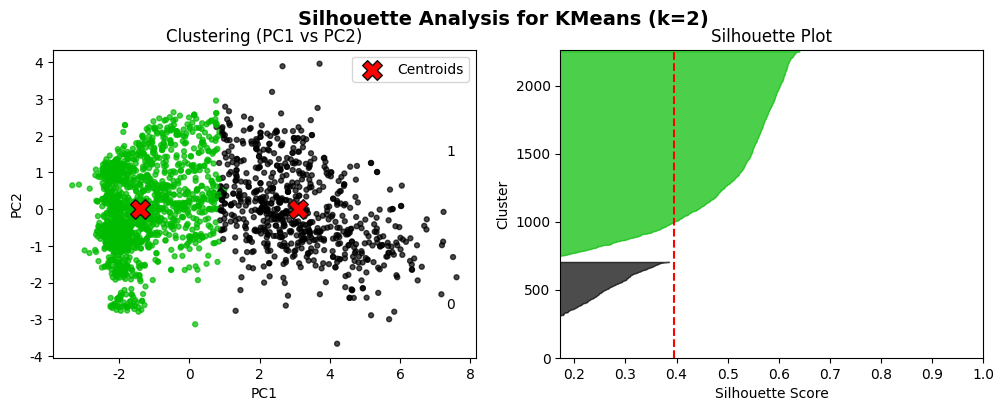

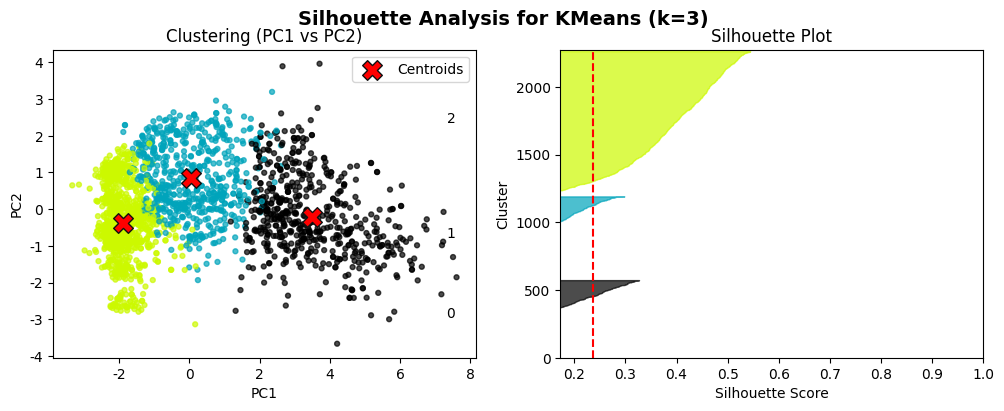

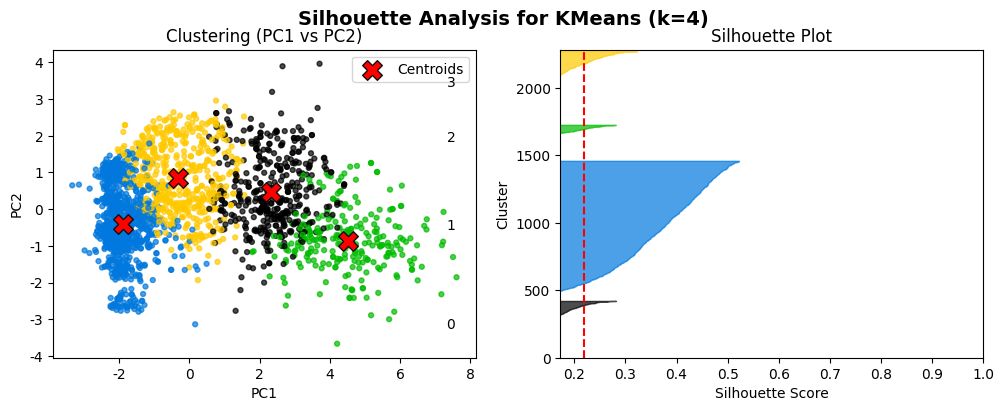

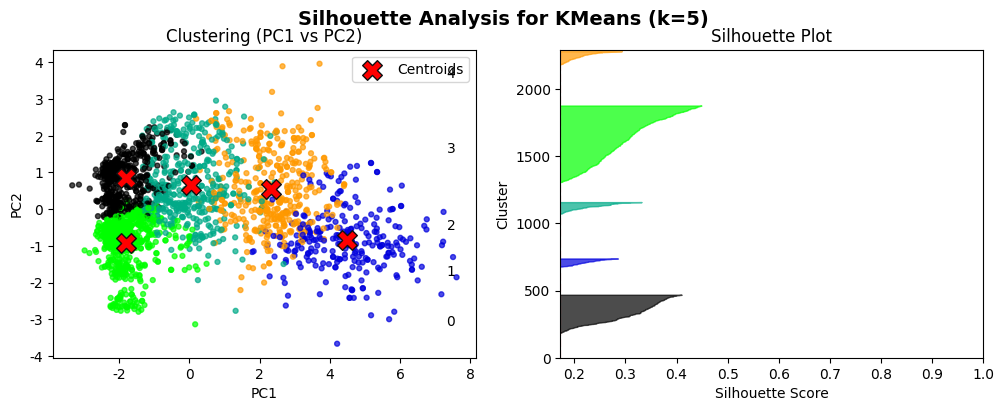

In [ ]:
from sklearn.metrics import silhouette_score, silhouette_samples
import matplotlib.cm as cm
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import numpy as np

nbClusters = range(2, 6)

silhouettes = []
for k in nbClusters:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_pca)
    silhouettes.append(silhouette_score(X_pca, labels))
xmin = min(silhouettes)

for k in nbClusters:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_pca)

    silhouette_avg = silhouette_score(X_pca, labels)
    silhouette_values = silhouette_samples(X_pca, labels)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    ax1.set_title('Clustering (PC1 vs PC2)')
    ax1.set_xlabel('PC1')
    ax1.set_ylabel('PC2')

    colors = cm.nipy_spectral(labels.astype(float) / k)
    ax1.scatter(X_pca[:, 0], X_pca[:, 1], marker='.', c=colors, s=50, alpha=0.7)

    centroids = model.cluster_centers_
    ax1.scatter(centroids[:, 0], centroids[:, 1],
                marker='X', c='red', s=200, edgecolor='k', label='Centroids')
    ax1.legend()

    ax2.set_xlim([xmin, 1])
    ax2.set_ylim([0, len(X_pca) + (k + 1) * 10])
    ax2.set_title('Silhouette Plot')
    ax2.set_xlabel('Silhouette Score')
    ax2.set_ylabel('Cluster')

    ax2.axvline(x=silhouette_avg, color='red', linestyle='--')

    y_lower = 10
    for i in range(k):
        cluster_silhouette_values = silhouette_values[labels == i]
        cluster_silhouette_values.sort()
        size_cluster = cluster_silhouette_values.shape[0]
        y_upper = y_lower + size_cluster

        color = cm.nipy_spectral(float(i) / k)
        ax2.fill_betweenx(np.arange(y_lower, y_upper), 0, cluster_silhouette_values,
                          facecolor=color, edgecolor=color, alpha=0.7)
        ax2.text(-0.05, y_lower + 0.5 * size_cluster, str(i))
        y_lower = y_upper + 10

    plt.suptitle(f'Silhouette Analysis for KMeans (k={k})', fontsize=14, fontweight='bold')
    plt.show()


So sánh AP vs KMeans

In [ ]:
kmeans_2 = KMeans(n_clusters=2, random_state=42, n_init=10)
labels_2 = kmeans_2.fit_predict(X_pca)

kmeans_sil_score = silhouette_score(X_pca, labels_2)

In [ ]:
print(f"AP: {ap_n_clusters} cụm")
print(f"K-Means: {n_clusters} cụm (dựa trên Silhouette / Elbow)")


AP: 2 cụm
K-Means: 2 cụm (dựa trên Silhouette / Elbow)


In [ ]:
print(f"Silhouette AP: {ap_sil_score1:.4f}")
print(f"Silhouette K-Means: {kmeans_sil_score:.4f}")


Silhouette AP: 0.4059
Silhouette K-Means: 0.3958


 AP -> tách biệt hơn\
 K-Means -> ít rõ hơn

## so sánh với HAC


In [ ]:
from scipy.cluster import hierarchy

Z = hierarchy.linkage(X_pca, method='ward')
print("Khoảng cách liên cụm lớn nhất:", Z[:, 2].max())


Khoảng cách liên cụm lớn nhất: 133.93791269398525


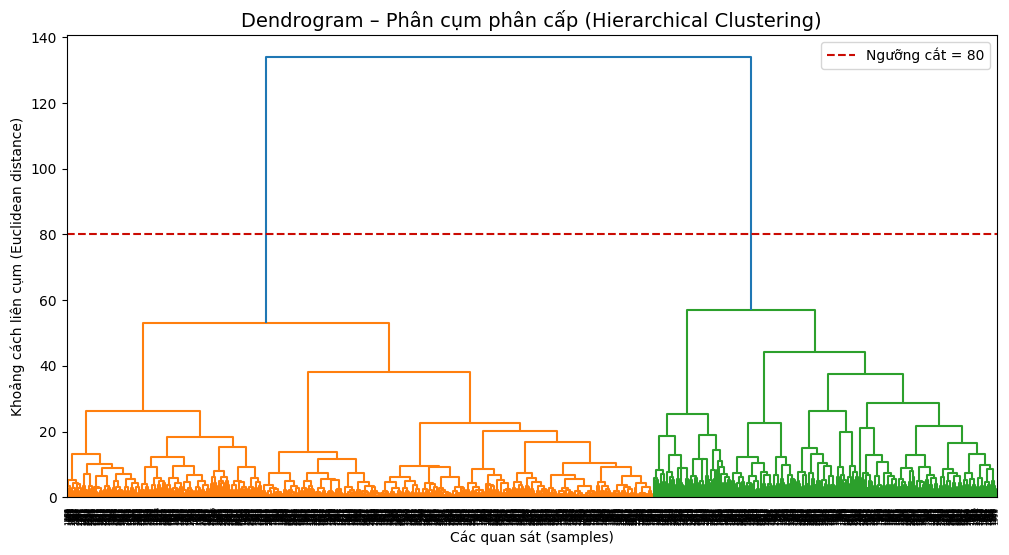

In [ ]:
from scipy.cluster import hierarchy
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.style.use('default')
plt.title("Dendrogram – Phân cụm phân cấp (Hierarchical Clustering)", fontsize=14)

Z = hierarchy.linkage(X_pca, method='ward')

dn = hierarchy.dendrogram(Z, color_threshold=80)

cut_height = 80
plt.axhline(y=cut_height, color='r', linestyle='--', label=f'Ngưỡng cắt = {cut_height}')

plt.xlabel("Các quan sát (samples)")
plt.ylabel("Khoảng cách liên cụm (Euclidean distance)")
plt.legend()
plt.show()


Agglomerative Clustering

In [ ]:
k = 2
hac_model = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage='ward')

In [ ]:
hac_labels = hac_model.fit_predict(X_pca)

In [ ]:
sil_hac = silhouette_score(X_pca, hac_labels)
print(f"Silhouette HAC: {sil_hac:.4f}")

Silhouette HAC: 0.3537


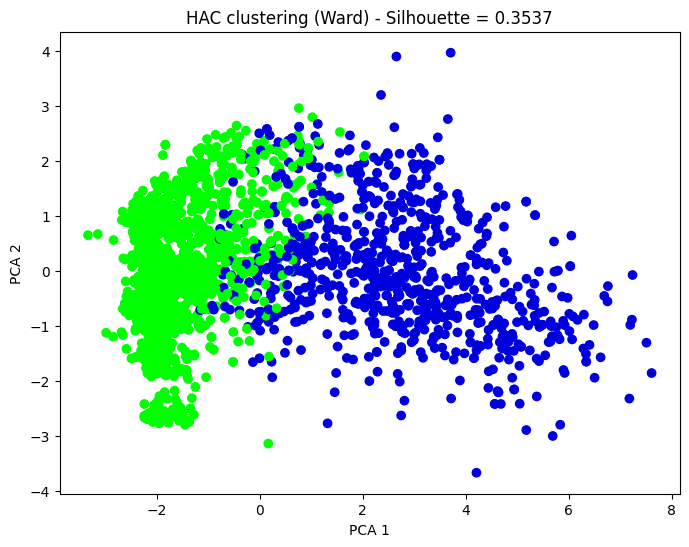

In [ ]:
fav_colors = [colors[0], colors[1]]
deep_cmap = ListedColormap(fav_colors)
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=hac_labels, cmap=deep_cmap)
plt.title(f"HAC clustering (Ward) - Silhouette = {sil_hac:.4f}")
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.show()

In [ ]:
print(f"Silhouette AP: {ap_sil_score1:.4f}")
print(f"Silhouette HAC: {sil_hac:.4f}")

Silhouette AP: 0.4059
Silhouette HAC: 0.3537


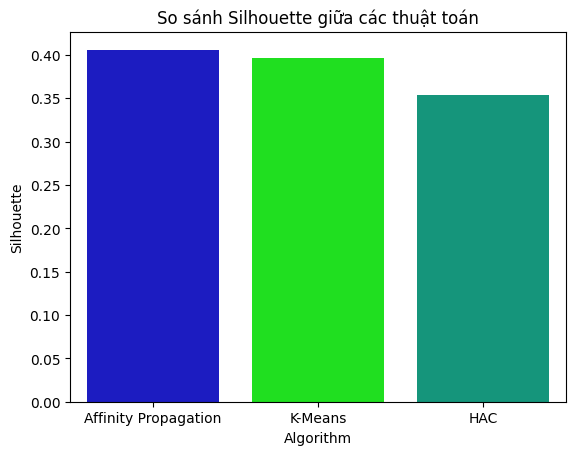

In [ ]:
import seaborn as sns
import pandas as pd

scores = pd.DataFrame({
    'Algorithm': ['Affinity Propagation', 'K-Means', 'HAC'],
    'Silhouette': [ap_sil_score1, kmeans_sil_score, sil_hac]
})

sns.barplot(data=scores, x='Algorithm', y='Silhouette', palette=[colors[0],colors[1],colors[6]])
plt.title('So sánh Silhouette giữa các thuật toán')
plt.show()


In [ ]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

results = []

ap_metrics = {
    'Model': 'Affinity Propagation',
    'n_clusters': k,
    'Silhouette': ap_sil_score1,
    'Davies-Bouldin': davies_bouldin_score(X_pca, ap_labels),
    'Calinski-Harabasz': calinski_harabasz_score(X_pca, ap_labels)
}
results.append(ap_metrics)

kmeans_metrics = {
    'Model': 'K-Means',
    'n_clusters': k,
    'Silhouette': kmeans_sil_score,
    'Davies-Bouldin': davies_bouldin_score(X_pca, labels),
    'Calinski-Harabasz': calinski_harabasz_score(X_pca, labels)
}
results.append(kmeans_metrics)

hac_metrics = {
    'Model': 'Hierarchical Clustering',
    'n_clusters': k,
    'Silhouette': sil_hac,
    'Davies-Bouldin': davies_bouldin_score(X_pca, hac_labels),
    'Calinski-Harabasz': calinski_harabasz_score(X_pca, hac_labels)
}
results.append(hac_metrics)

import pandas as pd
df_results = pd.DataFrame(results)
print(df_results)


                     Model  n_clusters  Silhouette  Davies-Bouldin  \
0     Affinity Propagation           2    0.405947        1.198967   
1                  K-Means           2    0.395841        1.799520   
2  Hierarchical Clustering           2    0.353742        1.307486   

   Calinski-Harabasz  
0        1329.812870  
1         648.381062  
2        1186.035175  


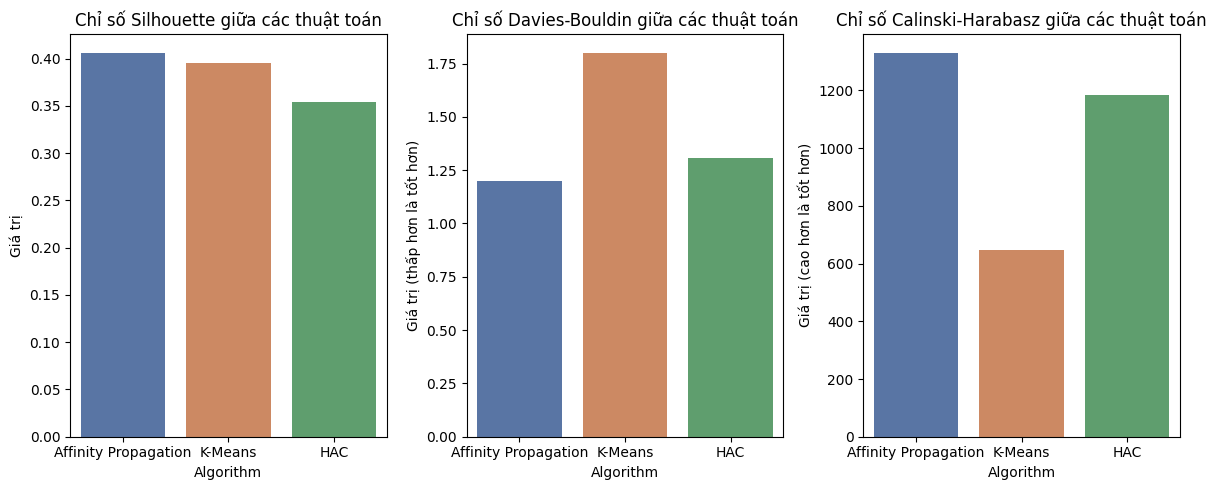

In [ ]:
colors = sns.color_palette("deep")
colors

scores = pd.DataFrame({
    'Algorithm': ['Affinity Propagation', 'K-Means', 'HAC'],
    'Silhouette': [ap_sil_score1, kmeans_sil_score, sil_hac],
    'Davies-Bouldin': [
        davies_bouldin_score(X_pca, ap_labels),
        davies_bouldin_score(X_pca, labels),
        davies_bouldin_score(X_pca, hac_labels)
    ],
    'Calinski-Harabasz': [
        calinski_harabasz_score(X_pca, ap_labels),
        calinski_harabasz_score(X_pca, labels),
        calinski_harabasz_score(X_pca, hac_labels)
    ]
})

fig, axes = plt.subplots(1, 3, figsize=(12, 5))

sns.barplot(data=scores, x='Algorithm', y='Silhouette',
            palette=[colors[0], colors[1], colors[2]], ax=axes[0])
axes[0].set_title('Chỉ số Silhouette giữa các thuật toán')
axes[0].set_ylabel('Giá trị')

sns.barplot(data=scores, x='Algorithm', y='Davies-Bouldin',
            palette=[colors[0], colors[1], colors[2]], ax=axes[1])
axes[1].set_title('Chỉ số Davies-Bouldin giữa các thuật toán')
axes[1].set_ylabel('Giá trị (thấp hơn là tốt hơn)')

sns.barplot(data=scores, x='Algorithm', y='Calinski-Harabasz',
            palette=[colors[0], colors[1], colors[2]], ax=axes[2])
axes[2].set_title('Chỉ số Calinski-Harabasz giữa các thuật toán')
axes[2].set_ylabel('Giá trị (cao hơn là tốt hơn)')

plt.tight_layout()
plt.show()


In [ ]:
!pip install memory_profiler


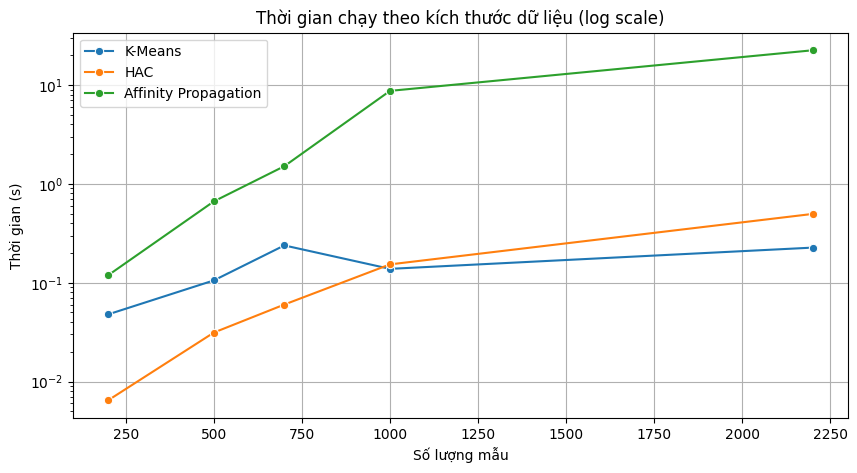

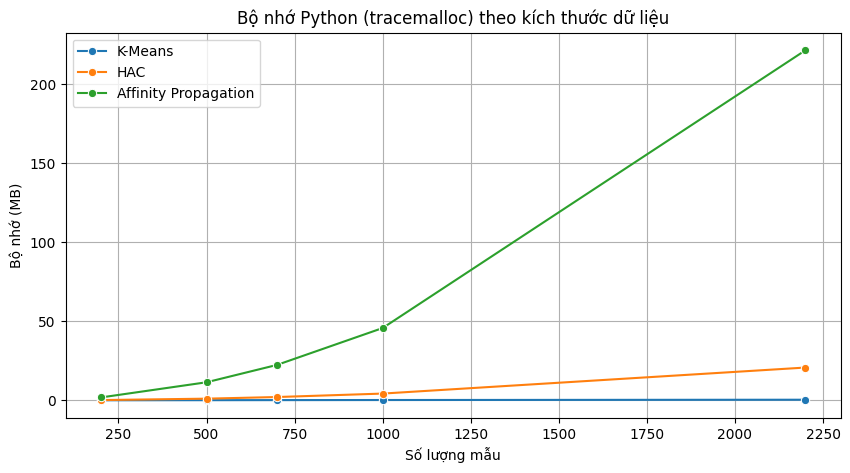

,Algorithm,Data Size,Time (s),"Memory (MB, Python)"
0,K-Means,200,0.047794,0.059055
1,HAC,200,0.006461,0.179800
2,Affinity Propagation,200,0.118916,1.838516
3,K-Means,500,0.105461,0.119324
4,HAC,500,0.031286,1.076906
5,Affinity Propagation,500,0.664419,11.451534
6,K-Means,700,0.238213,0.165100
7,HAC,700,0.060069,2.105993
8,Affinity Propagation,700,1.508186,22.437897
9,K-Means,1000,0.137980,0.219971


In [ ]:
import time
import gc
import tracemalloc
from sklearn.utils import resample
from memory_profiler import memory_usage

X_large = X_pca
algorithms = {
    "K-Means": lambda X: KMeans(n_clusters=3, n_init=10, random_state=42).fit(X),
    "HAC": lambda X: AgglomerativeClustering(n_clusters=3, linkage='ward').fit(X),
    "Affinity Propagation": lambda X: AffinityPropagation(random_state=42).fit(X)
}
sample_sizes = [200, 500, 700, 1000, 2200]
results = []

for n in sample_sizes:
    X_sample = resample(X_large, n_samples=n, random_state=42)

    for name, algo in algorithms.items():
        gc.collect()

        start_time = time.time()

        def run_algo():
            algo(X_sample)


        tracemalloc.start()
        run_algo()
        current, peak = tracemalloc.get_traced_memory()
        tracemalloc.stop()
        peak_mem_trace = peak / (1024 ** 2)

        end_time = time.time()

        results.append({
            'Algorithm': name,
            'Data Size': n,
            'Time (s)': end_time - start_time,
            'Memory (MB, Python)': peak_mem_trace
        })

df_complexity = pd.DataFrame(results)

plt.figure(figsize=(10, 5))
sns.lineplot(data=df_complexity, x='Data Size', y='Time (s)', hue='Algorithm', marker='o')
plt.yscale('log')
plt.title('Thời gian chạy theo kích thước dữ liệu (log scale)')
plt.ylabel('Thời gian (s)')
plt.xlabel('Số lượng mẫu')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 5))
sns.lineplot(data=df_complexity, x='Data Size', y='Memory (MB, Python)', hue='Algorithm', marker='o')
plt.title('Bộ nhớ Python (tracemalloc) theo kích thước dữ liệu')
plt.ylabel('Bộ nhớ (MB)')
plt.xlabel('Số lượng mẫu')
plt.legend()
plt.grid(True)
plt.show()

df_complexity
